# Пари 31–32 · маршрут на 90 + 90 хвилин з повторенням пар 28–30

За два блоки по 90 хвилин ви згадаєте, що зробили на парах 28–30, і побудуєте карту вин: таблицю з 13 хімічними ознаками стиснете до двох осей так, щоб три сорти було видно на звичайному графіку.

| Блок | Час | Що робимо |
|---|---|---|
| **1** | 0:00–0:31 | Повторення: пара 28 → 29 → 30 і місток до нового модуля |
| | 0:31–1:30 | Пара 31 · SVD і зниження розмірності (практичне 7.1, завдання 1–2) |
| **2** | 0:00–1:30 | Пара 32 · PCA і порівняння з SVD (практичне 7.1, завдання 3–4) |

Час у кожному блоці йде від його початку. Усі команди запускайте **з кореня репозиторію** — з тієї папки, де лежить цей файл.

По дорозі є девʼять **міні-завдань** на 2–3 хвилини: одна змінена команда або один-два рядки коду. Їх робите ви самі, одразу після прикладу.

Маршрут є у двох формах: цей текст і ноутбук [PythonAI_Author_Lesson31_Lesson32.ipynb](PythonAI_Author_Lesson31_Lesson32.ipynb), де під кожною командою вже є її вивід і всі рисунки. Ноутбук відкривайте з кореня репозиторію, ядро — `.venv`. Комірки міні-завдань у ньому порожні: їх запускаєте ви.

Докладний варіант лише пар 31–32 на 180 хвилин: [Lesson31_32_plan_180.md](../PythonAI_Author_Lesson31_Lesson32/Lesson31_32_plan_180.md).

<a id="step-0"></a>
## Підготовка

Один спільний venv у корені (Python 3.10–3.14):

```text
python -m venv .venv
.venv\Scripts\activate          (Windows)
source .venv/bin/activate        (macOS / Linux)
python -m pip install -U pip
python -m pip install -r requirements.txt
```

Перевірка — три команди, по одній на кожну папку пар:

In [1]:
import os
import subprocess
import sys
from pathlib import Path

from IPython.display import Image, display

ROOT = Path.cwd()
assert (ROOT / "PythonAI_Author_Lesson31_Lesson32.md").exists(), "Відкрийте ноутбук із кореня репозиторію python61_ai"


def run(script, *args):
    """Запустити скрипт пари тим самим Python, що й ноутбук, і надрукувати його вивід."""
    env = dict(os.environ, PYTHONIOENCODING="utf-8")
    done = subprocess.run(
        [sys.executable, script, *args], cwd=ROOT, env=env,
        capture_output=True, text=True, encoding="utf-8", errors="replace",
    )
    print(done.stdout + done.stderr)


def show(path):
    display(Image(filename=str(ROOT / path)))

In [2]:
run("PythonAI_Author_Lesson27_Lesson28/Lesson28_04_word_explorer.py", "good")
run("PythonAI_Author_Lesson29_Lesson30/Lesson30_04_supportflow_bot.py", "how do i pay")
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py")

--- Word2Vec
слово       найближчі слова (косинусна схожість)
good        decent 0.73, sturdy 0.65, bad 0.65, great 0.63, lousy 0.62

--- GloVe
слово       найближчі слова (косинусна схожість)
good        better 0.89, sure 0.83, really 0.83, kind 0.83, very 0.83




Модель: LSTM + GloVe  параметрів 2 749 991  словник запитів 24 999  відповідей 171

Клієнт: how do i pay
Бот:    open the order and press request refund   (8 мс)
        слів поза навчальними запитами: i, pay; модель має для них вектори: i, pay




Карта: 178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці (PC1 36.2%, PC2 19.2%)

Вино №0, справжній сорт 0
   на карті: PC1 = +3.32, PC2 = +1.44
   сусіди:   №10 (сорт 0), №52 (сорт 0), №58 (сорт 0), №13 (сорт 0), №42 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Вино №70, справжній сорт 1
   на карті: PC1 = -1.57, PC2 = -0.88
   сусіди:   №61 (сорт 1), №112 (сорт 1), №127 (сорт 1), №129 (сорт 1), №122 (сорт 1)
   сусіди підказують сорт 1 (5 з 5)

Вино №150, справжній сорт 2
   на карті: PC1 = -2.32, PC2 = +2.36
   сусіди:   №176 (сорт 2), №172 (сорт 2), №169 (сорт 2), №166 (сорт 2), №168 (сорт 2)
   сусіди підказують сорт 2 (5 з 5)

Нове вино: середнє, але alcohol=14.5, proline=1500, flavanoids=3.5
   на карті: PC1 = +1.58, PC2 = +1.77
   сусіди:   №17 (сорт 0), №33 (сорт 0), №45 (сорт 0), №7 (сорт 0), №53 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Рисунок: results\wine_map.png

Карта не знає сортів: кольори додано вже після PCA. Нове вино не змінює осей —
для нього викликаєм

- [ ] перша друкує таблицю сусідів слова `good`;
- [ ] друга друкує відповідь бота;
- [ ] третя друкує `на них 55.4% розкиду таблиці`.

Інтернет і GPU не потрібні. Графіки скрипти зберігають у папку `results/` своєї пари, вікна matplotlib не відкриваються.

---

# Блок 1 · 90 хвилин

<a id="step-1"></a>
## Крок 1 · 0:00–0:11 · Повторення пари 28: слово як 100 чисел

In [3]:
run("PythonAI_Author_Lesson27_Lesson28/Lesson28_04_word_explorer.py", "good", "price")

--- Word2Vec
слово       найближчі слова (косинусна схожість)
good        decent 0.73, sturdy 0.65, bad 0.65, great 0.63, lousy 0.62
price       admission 0.67, costs 0.65, priced 0.64, mb 0.64, storage 0.64

--- GloVe
слово       найближчі слова (косинусна схожість)
good        better 0.89, sure 0.83, really 0.83, kind 0.83, very 0.83
price       prices 0.86, value 0.76, drop 0.75, stock 0.75, market 0.74




**Що побачите.** Word2Vec: `good → decent 0.73, sturdy 0.65, bad 0.65`. GloVe: `good → better 0.89`, `price → prices 0.86, value 0.76`.

Кожне слово — вектор зі 100 чисел. Слова, які вживають у схожих контекстах, мають близькі вектори; близькість міряємо косинусом.

**Зверніть увагу:** `bad` стоїть серед сусідів `good`. Вектор знає, що слова трапляються в однакових контекстах, а не що вони означають те саме.

**Міні-завдання 1 · 2 хв.** Знайдіть ще одне слово, у якого серед сусідів у GloVe є антонім. Підставте свої слова замість `hot`:

In [ ]:
run("PythonAI_Author_Lesson27_Lesson28/Lesson28_04_word_explorer.py", "hot")

Потім перевірте відому аналогію і порівняйте дві моделі:

In [ ]:
run("PythonAI_Author_Lesson27_Lesson28/Lesson28_04_word_explorer.py", "--analogy", "king", "man", "woman")

In [6]:
run("PythonAI_Author_Lesson27_Lesson28/Lesson28_02_similarity_pca.py")

=== 1. Завдання 6.2.3: таблиця сусідів
--- Word2Vec
цільове слово  близькі слова                       косинусна схожість
good           decent, sturdy, bad                 0.73, 0.65, 0.65
bad            good, tough, dumb                   0.65, 0.63, 0.63
quality        speaker, speakerphone, megapixel    0.72, 0.70, 0.68

--- GloVe
цільове слово  близькі слова                       косинусна схожість
good           better, sure, really                0.89, 0.83, 0.83
bad            worse, good, things                 0.79, 0.77, 0.77
quality        excellent, standards, performance   0.76, 0.73, 0.72

таблиця: results\neighbors.csv 

=== 2. Завдання 6.2.4: 20 найчастіших слів → PCA
слова: like, even, good, time, would, get, much, also, story, well, two, first, character, characters, see, way, really, make, life, little
results\word2vec_visualization.png  матриця (20, 100), дві компоненти пояснюють 20% дисперсії
results\glove_visualization.png  матриця (20, 100), дві компоненти поясн

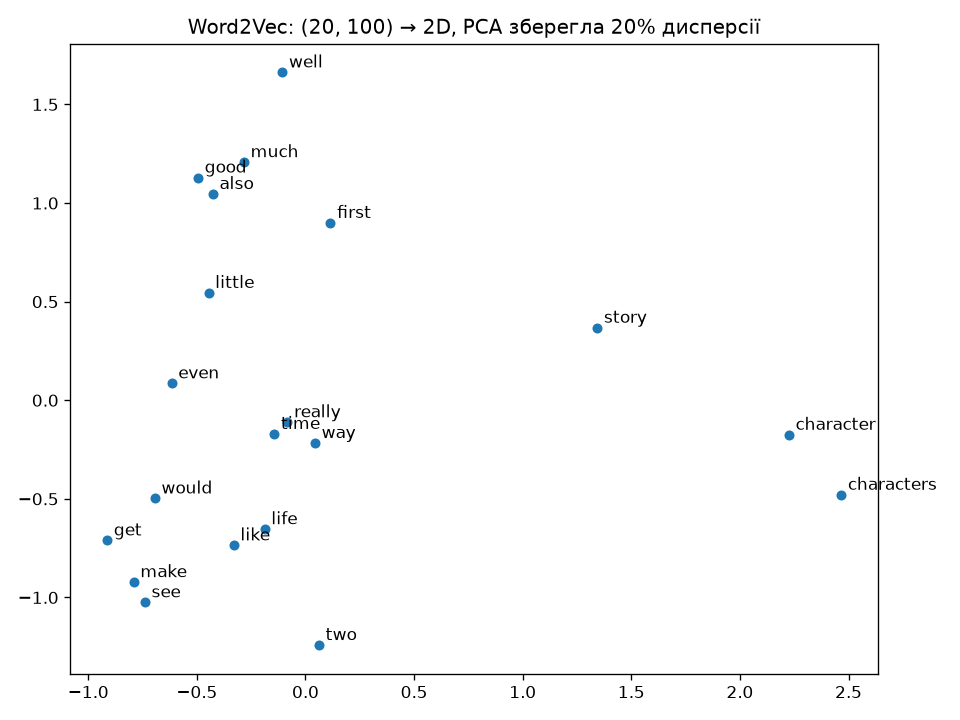

In [7]:
show("../PythonAI_Author_Lesson27_Lesson28/results/word2vec_visualization.png")

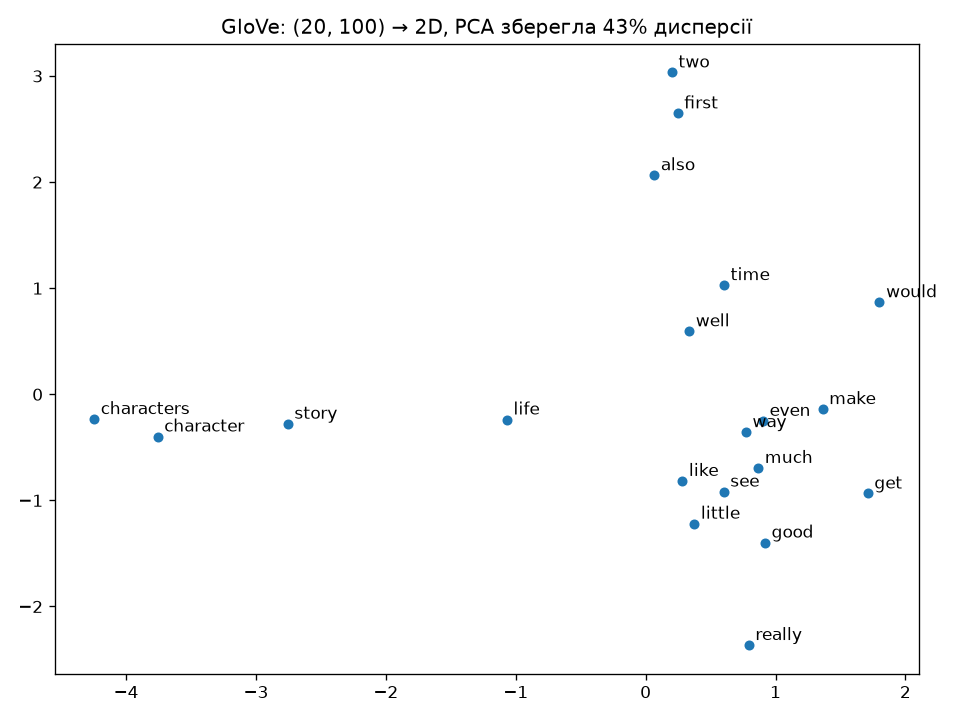

In [8]:
show("../PythonAI_Author_Lesson27_Lesson28/results/glove_visualization.png")

**Що побачите (~10 с).** Таблицю сусідів і два рисунки. Для Word2Vec: `матриця (20, 100), дві компоненти пояснюють 20% дисперсії`, для GloVe — 43%.

![20 слів на площині](../PythonAI_Author_Lesson27_Lesson28/results/word2vec_visualization.png)

Сто чисел на слово стали двома — це зробив PCA. Запамʼятайте число 20%: наприкінці заняття ви знатимете, що воно означає і чому таке мале.

In [9]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson28_05_words_to_sequences.py")

GloVe: 24995 слів по 100 чисел

1) Сусіди слів служби підтримки
   password  login 0.68, username 0.66, user 0.66, firewall 0.58, database 0.57
   order     to 0.74, allow 0.74, take 0.73, must 0.73, thus 0.72
   refund    refunds 0.85, payment 0.71, rebate 0.65, fees 0.64, checks 0.64
   delivery  deliveries 0.71, supplies 0.59, supply 0.58, dropped 0.58, crude 0.58
   late      early 0.91, earlier 0.81, after 0.81, last 0.79, ago 0.78

2) Бот-пошуковик: найближчий запит з бази SupportFlow
   i cannot remember my passcode       → She forgot my password.              0.65 ✓
   how do i recover my login           → How can She reset my password?       0.54 ✓
   where is my parcel                  → How much does delivery cost?         0.33 ✗
   my package is late                  → How can She return an item?          0.70 ✗
   the delivery is late                → How long does delivery take?         0.80 ✗
   i want my cash back                 → When will She get my money back?     0

**Що побачите.** Пошуковик на середньому векторі запиту знаходить правильну відповідь для 11 з 15 перефразованих запитів. А ще `cos("you can cancel it", "can you cancel it") = 1.000`.

**Зверніть увагу:** середній вектор речення не бачить порядку слів. Ствердження і питання для нього однакові.

**Перевір себе:**
1. Вектор слова — це 100 чисел. Як слова опинилися на площині і яку частку розкиду при цьому втрачено?
2. Чому `cos("refund before delivery", "delivery before refund") = 1`?

<a id="step-2"></a>
## Крок 2 · 0:11–0:19 · Повторення пари 29: модель, що пише відповідь по слову

In [10]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson29_01_prepare_data.py")

1) 15 пар запит → відповідь (assets/supportflow_qa.csv)
   'How can She reset my password?' → 'You can reset it through the account settings.'
   ['how', 'can', 'she', 'reset', 'my', 'password'] → ['you', 'can', 'reset', 'it', 'through', 'the', 'account', 'settings']
   'She forgot my password.' → 'Click forgot password on the login page and check your email.'
   ['she', 'forgot', 'my', 'password'] → ['click', 'forgot', 'password', 'on', 'the', 'login', 'page', 'and', 'check', 'your', 'email']
   'My account is locked.' → 'Wait fifteen minutes or contact support to unlock it.'
   ['my', 'account', 'is', 'locked'] → ['wait', 'fifteen', 'minutes', 'or', 'contact', 'support', 'to', 'unlock', 'it']

2) Словник: 104 токенів, з них 4 спеціальні
   <pad>=0, <unk>=1, <sos>=2, <eos>=3, how=4, can=5, she=6, reset=7, my=8, password=9, forgot=10, account=11, is=12, locked=13, where=14, order=15, …

3) Максимальна довжина: запит 7 токенів, відповідь 11 токенів
   найдовша відповідь: 'click forgot p

**Що побачите.** 15 пар «запит → відповідь», словник на 104 токени, з них 4 спеціальні. Нове слово `passcode` стає `<unk>=1`.

| Токен | Навіщо |
|---|---|
| `<pad>` | доповнити коротке речення до спільної довжини |
| `<unk>` | слово, якого немає у словнику |
| `<sos>` | «почни відповідь» |
| `<eos>` | «відповідь закінчено» |

Мовна модель робить одне: за словами, які вже є, вгадує наступне. Текст для неї — послідовність номерів зі словника.

In [11]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson29_03_train_rnn.py")

Модель: encoder nn.RNN + decoder nn.RNN + nn.Linear(128 → 104); вхід: one-hot, input_size = 104
Параметрів: 73 320; пар: 15; batch 8

1) 10 епох, як в аркуші 6.3
     епоха    1   loss 4.636
     епоха    2   loss 4.579
     епоха    3   loss 4.518
     епоха    4   loss 4.437
     епоха    5   loss 4.320
     епоха    6   loss 4.172
     епоха    7   loss 4.034
     епоха    8   loss 3.943
     епоха    9   loss 3.869
     епоха   10   loss 3.794
   відповіді після 10 епох:
     How can I reset my password?  → you can the
     Where is my order?            → you can the
     I was charged twice.          → you can the
   Loss ще високий: 10 епох × 2 кроки Adam з lr 0.001 — це лише 20 оновлень ваг.

2) Ще 140 епох (разом 150)
     епоха    1   loss 3.742
     епоха   25   loss 2.706
     епоха   50   loss 1.967
     епоха   75   loss 1.110
     епоха  100   loss 0.546
     епоха  125   loss 0.262
   відповіді після 150 епох:
     How can I reset my password?  → you can reset it through

In [12]:
show("../PythonAI_Author_Lesson29_Lesson30/results/rnn_loss.png")

**Що побачите (~7 с).** Після 10 епох loss 4.6 → 3.8, і на всі запити модель відповідає `you can the`. Після 150 епох — 100% дослівно правильних відповідей на навчальних запитах і 50% на перефразованих. На `i cannot remember my passcode` модель відповідає про відстеження замовлення.

RNN читає слова по одному і тримає стан — памʼять про прочитане. Seq2seq складається з двох таких мереж: енкодер стискає запит у вектор, декодер із нього пише відповідь.

**Міні-завдання 2 · 2 хв.** Між 10 і 150 епохами модель десь починає відповідати правильно. Запустіть навчання на 60 і на 90 епох і подивіться на рядок «дослівно правильних на навчальних запитах»:

In [ ]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson29_03_train_rnn.py", "--epochs", "60")
run("PythonAI_Author_Lesson29_Lesson30/Lesson29_03_train_rnn.py", "--epochs", "90")

Після скількох епох зʼявляються перші правильні відповіді?

**Перевір себе:**
3. Модель правильно відповіла на всі навчальні запити. Чому це ще не означає, що вона їх розуміє?

<a id="step-3"></a>
## Крок 3 · 0:19–0:28 · Повторення пари 30: три способи це полагодити

In [14]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson30_02_transfer_glove.py")

1) Чого модель «з нуля» не бачила ніколи, а GloVe знає
   25 слів нових запитів немає в 30 навчальних парах: application, cannot, cash, fast, home, i, late, mail, me, need, package, parcel, passcode, person, price, real, recover, reimbursement, rejected, remember, shipping, they, times, too, took
   у GloVe є 25 з них
   найближче змістовне навчальне слово за GloVe: need → want 0.87, cash → money 0.85, fast → slow 0.80, took → take 0.77, mail → email 0.76, rejected → accept 0.76, remember → want 0.74, home → back 0.73
   найслабші: recover → return 0.58, parcel → discount 0.38, passcode → password 0.26

2) Чотири варіанти LSTM, 150 епох, seed 0…2
   з нуля готово
   GloVe, заморожено готово
   GloVe, донавчання готово
   freeze → unfreeze готово

   варіант               нові exact   нові F1   навчається параметрів     час
   --------------------  -----------  --------  ------------------------  ------
   з нуля                29% ± 3%     0.49      242 860                   4.8 с
   G

Скрипт працює близько хвилини: навчає чотири варіанти моделі по три рази. Поки він рахує, згадайте три ідеї пари 30.

1. **LSTM.** Окрема лінія памʼяті та ворота: що забути, що записати, що показати. Памʼятає довше за просту RNN.
2. **Увага.** На кожному кроці модель сама вирішує, на які слова запиту дивитись. З неї виріс трансформер.
3. **Transfer learning.** Беремо шар, навчений на мільярдах слів, заморожуємо його і вчимо лише решту.

**Що побачите.**

| Варіант | Нові запити, дослівно |
|---|---|
| LSTM з нуля | 29% |
| LSTM + GloVe, заморожено | 53% |
| пошуковик з пари 28 | 73% |

У першому розділі виводу: `cash → money 0.85`, `need → want 0.87`. Модель з GloVe розуміє слова, яких не було в навчальних даних, бо їхні вектори лежать поруч зі знайомими.

In [15]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson30_04_supportflow_bot.py", "i cannot remember my passcode", "my passcode", "i cannot remember")

Модель: LSTM + GloVe  параметрів 2 749 991  словник запитів 24 999  відповідей 171

Клієнт: i cannot remember my passcode
Бот:    click forgot password on the login page and check your email   (9 мс)
        слів поза навчальними запитами: i, cannot, remember, passcode; модель має для них вектори: i, cannot, remember, passcode

Клієнт: my passcode
Бот:    click forgot password on the login page and check your email   (5 мс)
        слів поза навчальними запитами: passcode; модель має для них вектори: passcode

Клієнт: i cannot remember
Бот:    yes we ship to most countries   (5 мс)
        слів поза навчальними запитами: i, cannot, remember; модель має для них вектори: i, cannot, remember




**Що побачите.** На перші два запити бот відповідає про скидання пароля. На третій, без слова `passcode`, — про доставку.

**Міні-завдання 3 · 2 хв.** Той самий прийом на іншому запиті: викидайте слова по одному і знайдіть, на якому тримається відповідь.

In [ ]:
run("PythonAI_Author_Lesson29_Lesson30/Lesson30_04_supportflow_bot.py", "where is my parcel", "my parcel", "where is my")

Відповідь тримається на слові `parcel` чи на чомусь іншому?

**Зверніть увагу:** на 30 прикладах мову не вивчити. Знання приходять з великої готової моделі. А порівнювати моделі треба чесно: однакові умови і кілька запусків.

**Перевір себе:**
4. Слова `passcode` немає в навчальних даних. Звідки бот знає, що це про пароль?

<a id="step-4"></a>
## Крок 4 · 0:28–0:31 · Місток: від відповідей до будови даних

1. Досі завжди була правильна відповідь: ціна, діагноз, наступне слово. Модель вчилась на парах «вхід → відповідь». Це навчання з учителем.
2. Тепер відповіді немає. Є лише таблиця, і питання інше: як ці дані влаштовані? Це навчання без учителя, модуль 7.
3. Ви вже це робили на кроці 1: сто чисел на слово стали двома.
4. Сьогодні ви дізнаєтесь, як стиснути багато ознак у дві, втративши якомога менше, і як порахувати, скільки втрачено.

<a id="step-5"></a>
## Крок 5 · 0:31–0:38 · Пара 31 · готова карта вин

In [17]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py")
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py", "--new", "alcohol=14.5", "proline=1500", "flavanoids=3.5")

Карта: 178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці (PC1 36.2%, PC2 19.2%)

Вино №0, справжній сорт 0
   на карті: PC1 = +3.32, PC2 = +1.44
   сусіди:   №10 (сорт 0), №52 (сорт 0), №58 (сорт 0), №13 (сорт 0), №42 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Вино №70, справжній сорт 1
   на карті: PC1 = -1.57, PC2 = -0.88
   сусіди:   №61 (сорт 1), №112 (сорт 1), №127 (сорт 1), №129 (сорт 1), №122 (сорт 1)
   сусіди підказують сорт 1 (5 з 5)

Вино №150, справжній сорт 2
   на карті: PC1 = -2.32, PC2 = +2.36
   сусіди:   №176 (сорт 2), №172 (сорт 2), №169 (сорт 2), №166 (сорт 2), №168 (сорт 2)
   сусіди підказують сорт 2 (5 з 5)

Нове вино: середнє, але alcohol=14.5, proline=1500, flavanoids=3.5
   на карті: PC1 = +1.58, PC2 = +1.77
   сусіди:   №17 (сорт 0), №33 (сорт 0), №45 (сорт 0), №7 (сорт 0), №53 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Рисунок: results\wine_map.png

Карта не знає сортів: кольори додано вже після PCA. Нове вино не змінює осей —
для нього викликаєм

Карта: 178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці (PC1 36.2%, PC2 19.2%)

Нове вино: середнє, але alcohol=14.5, proline=1500, flavanoids=3.5
   на карті: PC1 = +1.58, PC2 = +1.77
   сусіди:   №17 (сорт 0), №33 (сорт 0), №45 (сорт 0), №7 (сорт 0), №53 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Рисунок: results\wine_map.png



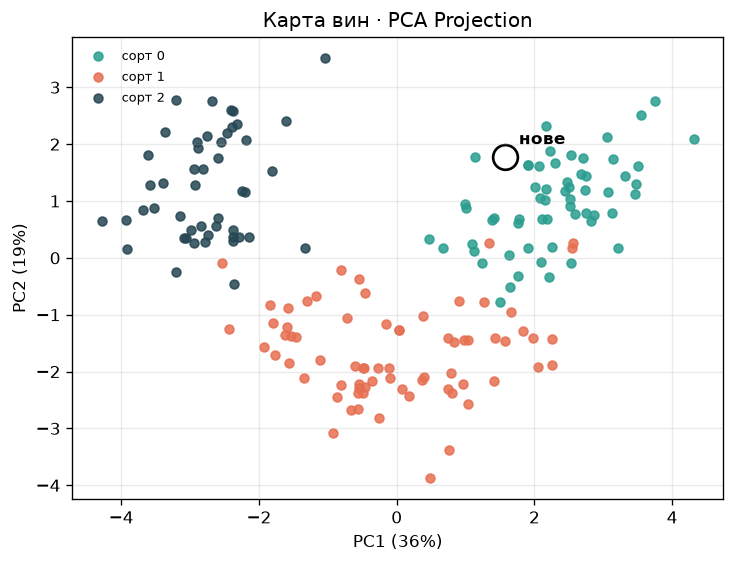

In [18]:
show("../PythonAI_Author_Lesson31_Lesson32/results/wine_map.png")

**Що побачите.** `178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці`. У вин №0, №70 і №150 усі пʼять найближчих сусідів — того самого сорту. Нове вино потрапляє в точку `PC1 = +1.58, PC2 = +1.77`, і сусіди підказують сорт 0.

Відкрийте `PythonAI_Author_Lesson31_Lesson32/results/wine_map.png`: три кольорові хмари майже не перетинаються.

**Зверніть увагу:** програма сортів не бачила. Кольори додано вже після обчислень.

**Міні-завдання 4 · 2 хв.** Придумайте вино, яке потрапить до сорту 2. Спершу подивіться, які є ознаки і в яких межах вони змінюються, потім підставте свої значення:

In [ ]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py", "--features")
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py", "--new", "color_intensity=5", "hue=1.0")

Змінюйте не більше трьох ознак. Які з них найсильніше зсувають точку на карті?

<a id="step-6"></a>
## Крок 6 · 0:38–0:50 · Таблиця wine і StandardScaler (завдання 7.1.1)

У презентації 31: «Старт: навіщо стискати таблицю», «StandardScaler перед SVD», «Приклад · z-score на двох стовпцях».

In [20]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson31_01_prepare_wine.py")

1) DataFrame (178, 14): 13 ознак + стовпець target. Матриця ознак X — (178, 13)
   сортів: 0 → 59 вин, 1 → 71 вин, 2 → 48 вин
 alcohol  malic_acid  color_intensity  hue  proline  target
   14.23        1.71             5.64 1.04   1065.0       0
   13.20        1.78             4.38 1.05   1050.0       0
   13.16        2.36             5.68 1.03   1185.0       0

2) Масштаби ознак дуже різні (від найбільшого розкиду до найменшого)
                        mean     std     min      max
proline               746.89  314.91  278.00  1680.00
magnesium              99.74   14.28   70.00   162.00
alcalinity_of_ash      19.49    3.34   10.60    30.00
hue                     0.96    0.23    0.48     1.71
nonflavanoid_phenols    0.36    0.12    0.13     0.66
   proline дає 99.8% усієї дисперсії таблиці — лише через одиниці вимірювання.

3) Після StandardScaler кожен стовпець має середнє 0 і розкид 1
   середнє по стовпцях: від -8.4e-16 до 3.6e-16
   std по стовпцях:     від 1.000 до 1.000
   те

**Що побачите.** `DataFrame (178, 14)`: 13 ознак і `target`. Матриця ознак `(178, 13)`, сортів 59 / 71 / 48. `proline` змінюється від 278 до 1680, `hue` — від 0.48 до 1.71. Через це `proline` дає 99.8% усієї дисперсії таблиці. Після `StandardScaler` кожна ознака дає 7.7%.

z-score руками: `(x − mean) / std`. Для `proline[0] = 1065` це `(1065 − 746.9) / 314.0 = 1.013`, і scaler дає те саме.

**Зверніть увагу:** `target` лежить у `DataFrame`, але не в матриці `X`. Сорт потрібен лише для кольору точок.

**Перевір себе:**
5. Що зміниться в таблиці дисперсій, якщо `proline` записати не в міліграмах, а в грамах?
6. Чому 13 ознак не можна показати на одному графіку?

<a id="step-7"></a>
## Крок 7 · 0:50–1:04 · SVD-розклад руками

У презентації 31: «TruncatedSVD як дві нові осі», «Приклад · проєкція 4 точок на 2 компоненти».

In [21]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson31_02_svd_by_hand.py")

1) Маленька таблиця 4 × 3 (4 покупці оцінили 3 товари)
[[5. 4. 1.]
 [4. 5. 1.]
 [1. 1. 5.]
 [2. 1. 4.]]
   U (4, 3), S [10.06  5.42  1.14], Vᵀ (3, 3)
   U·S·Vᵀ повертає таблицю: похибка 2.7e-15

2) Залишаємо k найбільших сингулярних чисел
   k=1: похибка 5.54 = корінь із суми відкинутих s² = 5.54
   k=2: похибка 1.14 = корінь із суми відкинутих s² = 1.14
   наближення рангу 2:
[[4.52 4.47 1.05]
 [4.52 4.48 0.95]
 [1.25 0.75 4.97]
 [1.69 1.3  4.03]]
   нові координати рядків Z = U·S (4 × 2):
[[-6.18  1.84]
 [-6.14  1.94]
 [-3.46 -3.86]
 [-3.67 -2.7 ]]

3) Wine після scaler: (178, 13), сингулярних чисел 13
   s  = [28.9 21.1 16.  12.8 12.3] …
   частка s² = [0.36 0.19 0.11 0.07 0.07] …

4) Дві компоненти трьома способами
   U·S і X·V збігаються:            4.4e-15
   numpy і TruncatedSVD збігаються: 8.4e-15  (з точністю до знака осі)

5) Скільки таблиці зберігає k компонент
    k   частка s²   відносна похибка відновлення
    1      36.2%      79.9%
    2      55.4%      66.8%
    3     

**Що побачите.**
1. Таблицю 4 × 3 розкладено на `U`, `S = [10.06, 5.42, 1.14]` і `Vᵀ`. Добуток `U·S·Vᵀ` повертає таблицю.
2. Якщо лишити одне сингулярне число, похибка 5.54; якщо два — 1.14. Похибка дорівнює тому, що відкинули.
3. Для wine сингулярні числа `28.9, 21.1, 16.0, …`. Перші два тримають 36.2% і 19.2%.

| k | Частка | Похибка відновлення |
|---|---|---|
| 1 | 36.2% | 79.9% |
| 2 | 55.4% | 66.8% |
| 5 | 80.2% | 44.5% |
| 8 | 92.0% | 28.3% |
| 13 | 100% | 0% |

Перша вісь — суміш `flavanoids`, `total_phenols` і `od280/od315`. Друга — `color_intensity`, `alcohol` і `proline`.

**Часта пастка:** «дві компоненти» — це не два початкові стовпці. Кожна компонента складена з усіх 13 ознак з різними вагами.

**Міні-завдання 5 · 3 хв.** У таблиці немає рядка `k = 4`. Порахуйте його самі. Файл `PythonAI_Author_Lesson31_Lesson32/my_rank.py`:

In [22]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(load_wine().data)
s = np.linalg.svd(X_scaled, compute_uv=False)        # 13 сингулярних чисел
share = (s ** 2).cumsum() / (s ** 2).sum()            # накопичена частка: share[0] — це k = 1
print(share[1].round(3))                              # k = 2 → 0.554
# Міні-завдання 5: надрукуйте частку і похибку відновлення √(1 − частка) для k = 4

0.554


За якого найменшого `k` похибка відновлення стає меншою за 50%?

**Перевір себе:**
7. Чому знак компоненти може бути іншим на іншому компʼютері і чи є це помилкою?
8. Чому за `k = 13` похибка дорівнює нулю?

<a id="step-8"></a>
## Крок 8 · 1:04–1:20 · TruncatedSVD і SVD Projection (завдання 7.1.2)

У презентації 31: «Приклад · wine у 2D», «Як читати scatter SVD Projection».

In [23]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson31_03_svd_projection.py")

1) TruncatedSVD(n_components=2): (178, 13) → (178, 2)
   перші 3 вина в нових координатах:
[[ 3.32  1.44]
 [ 2.21 -0.33]
 [ 2.52  1.03]]
   explained_variance_ratio_ = [0.362 0.192], разом 55.4%
   графік: results\svd_projection.png

2) Той самий SVD без scaler
   кореляція SVD-1 з однією ознакою proline: 1.000
   перша вісь майже дорівнює proline: найбільші числа забрали всю увагу
   графік: results\svd_scaled_vs_raw.png

3) Наскільки добре карта розділяє сорти (kNN на двох координатах, 5-fold)
   без scaler:   70.3%
   після scaler: 96.6%
   усі 13 ознак: 95.5%
   SVD сортів не бачив. kNN тут лише лінійка, якою міряємо карту.



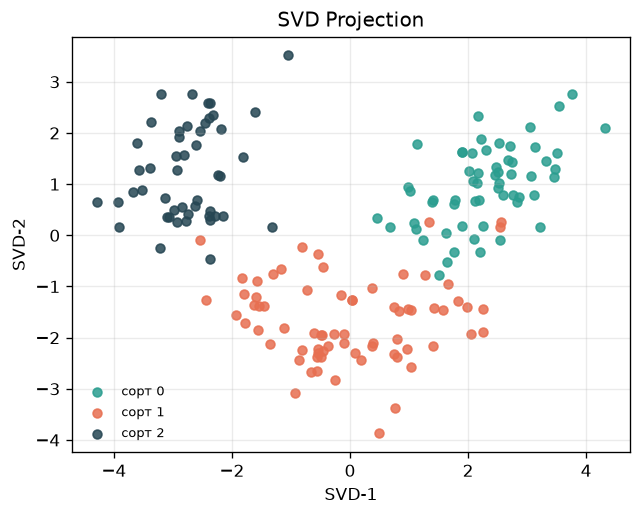

In [24]:
show("../PythonAI_Author_Lesson31_Lesson32/results/svd_projection.png")

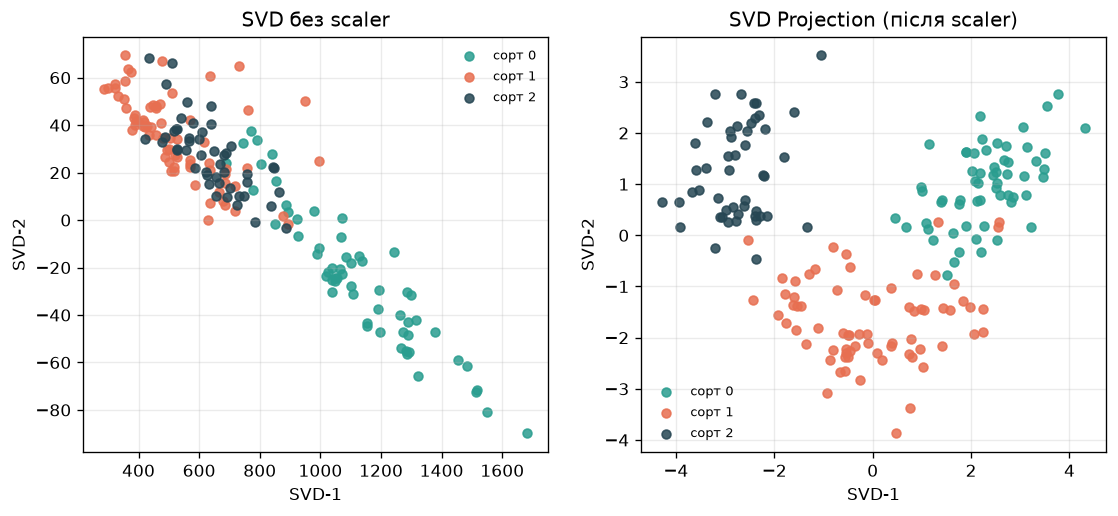

In [25]:
show("../PythonAI_Author_Lesson31_Lesson32/results/svd_scaled_vs_raw.png")

**Що побачите.** `TruncatedSVD(n_components=2)` перетворює `(178, 13)` на `(178, 2)`; `explained_variance_ratio_ = [0.362 0.192]`, разом 55.4%. Рисунки: `results/svd_projection.png` і `results/svd_scaled_vs_raw.png` (ліворуч без scaler, праворуч зі scaler).

| Дані | Точність kNN на координатах |
|---|---|
| 2 компоненти без scaler | 70.3% |
| 2 компоненти після scaler | 96.6% |
| усі 13 ознак після scaler | 95.5% |

**Зверніть увагу:** kNN тут — лінійка, якою ми міряємо якість карти. SVD сортів не бачив і нічого не класифікував.

**Напишіть самі.** Файл `PythonAI_Author_Lesson31_Lesson32/my_svd.py`:

(178, 14)
(178, 2) [0.362 0.192]


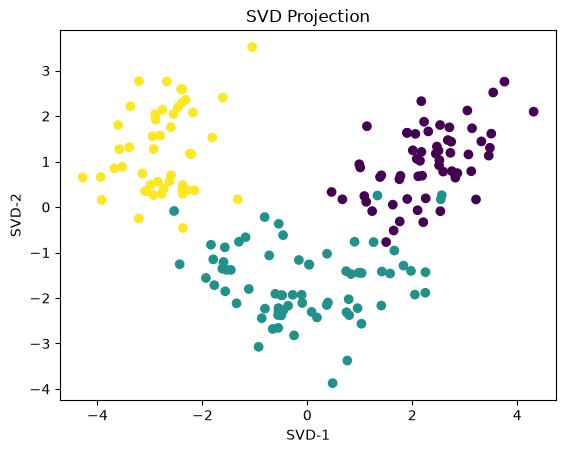

In [26]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

df = load_wine(as_frame=True).frame
print(df.shape)                                   # (178, 14)
X = df.drop(columns="target")                     # target не йде в SVD
X_scaled = StandardScaler().fit_transform(X)

# Міні-завдання 6: поставте n_components=3 і надрукуйте суму часток
# Міні-завдання 7 (блок 2): замініть TruncatedSVD на PCA
svd = TruncatedSVD(n_components=2, random_state=42)
Z = svd.fit_transform(X_scaled)                   # спробуйте X замість X_scaled
print(Z.shape, svd.explained_variance_ratio_.round(3))   # (178, 2) [0.362 0.192]

plt.scatter(Z[:, 0], Z[:, 1], c=df["target"])
plt.xlabel("SVD-1")
plt.ylabel("SVD-2")
plt.title("SVD Projection")
plt.show()

Потім замініть `X_scaled` на `X` у `fit_transform`, запустіть ще раз і порівняйте рисунки. Поверніть `X_scaled` назад.

**Міні-завдання 6 · 2 хв.** У своєму `my_svd.py` поставте `n_components=3` і надрукуйте `svd.explained_variance_ratio_.sum()`. Скільки розкиду додала третя вісь? Графік лишіть на перших двох осях.

**Перевір себе:**
9. Що буде з графіком, якщо масштабувати не до SVD, а після нього?

<a id="step-9"></a>
## Крок 9 · 1:20–1:26 · Навіщо саме TruncatedSVD

In [27]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson31_04_svd_text.py", "i lost my password")

1) TF-IDF: 30 текстів × 107 слів, ненульових клітинок 164 (5.1%)
   якщо відняти середнє стовпців (як робить PCA), ненульових стане 3210 (100%)
   на 100 000 документів × 50 000 слів така матриця не влізе в памʼять. TruncatedSVD її не центрує.

2) TruncatedSVD: (30, 107) → (30, 10). Кожна компонента — «тема», суміш слів
   компонента 1: item, order, warranty, cancel, delivery
   компонента 2: item, warranty, update, app, settings
   компонента 3: order, update, settings, cancel, profile

3) Найближчий сусід має ту саму тему (12 тем, 30 текстів)
   TF-IDF, 107 чисел на текст: 57%
   SVD, k=2                20%
   SVD, k=5                50%
   SVD, k=10               53%
   10 чисел замість 107 — і майже та сама якість. Двох чисел для 12 тем замало.

4) Пошук у стиснутому просторі (10 вимірів)
   'i lost my password' → [password] I forgot my password.

Карта текстів: results\svd_text_map.png
Той самий прийом на парі 28 робив PCA над векторами слів. Тут SVD працює прямо з таблицею частот

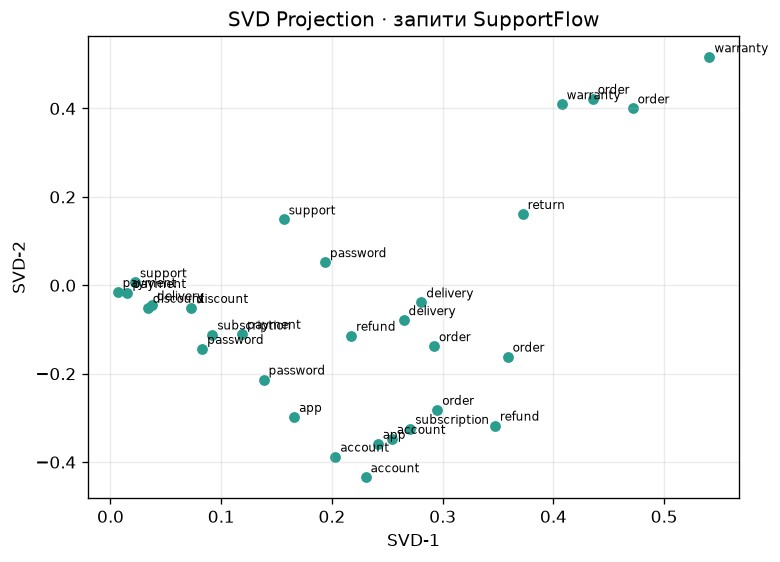

In [28]:
show("../PythonAI_Author_Lesson31_Lesson32/results/svd_text_map.png")

**Що побачите.** TF-IDF 30 запитів SupportFlow з кроку 3 — таблиця 30 × 107, де ненульових клітинок лише 5.1%. Якщо відняти середнє стовпців, ненульовими стануть усі 100%. Найближчий сусід має ту саму тему у 57% випадків на 107 числах, у 53% на 10 числах і лише у 20% на двох.

**Зверніть увагу:** `TruncatedSVD` даних не центрує, тому нулі лишаються нулями і велика таблиця текстів влазить у памʼять. Дві компоненти зручні для графіка, але для 12 тем їх замало: кількість компонент вибирають під задачу.

<a id="step-10"></a>
## Крок 10 · 1:26–1:30 · Перевір себе · пара 31

10. Навіщо зменшувати розмірність?
11. Чому scaler стоїть перед SVD?
12. Що повертає `fit_transform`?
13. Для чого на графіку колір `target`?

---

# Блок 2 · 90 хвилин

<a id="step-11"></a>
## Крок 11 · 0:00–0:05 · Повернення

Шлях пари 31: `DataFrame → X без target → StandardScaler → TruncatedSVD(2) → scatter`, і на двох осях лишилося 55.4% розкиду.

**Перевір себе:**
14. На кроці 1 PCA зберегла 20% розкиду 20 слів, а тут дві осі тримають 55.4%. Чому така різниця?

<a id="step-12"></a>
## Крок 12 · 0:05–0:20 · PCA і PCA Projection (завдання 7.1.3)

У презентації 32: «Старт: PCA як поворот осей», «Приклад · центр маси і нульове середнє», «PCA n_components=2».

PCA переносить початок координат у центр хмари точок і повертає осі так, щоб уздовж першої розкид був найбільший. Друга вісь перпендикулярна до першої і забирає найбільше з того, що лишилось.

In [29]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_01_pca_projection.py")

1) PCA(n_components=2): (178, 13) → (178, 2)
   перші 3 вина:
[[ 3.32  1.44]
 [ 2.21 -0.33]
 [ 2.52  1.03]]
   середнє нових координат: [0. 0.] — PCA центрує дані

2) explained_variance_ratio_ — частка розкиду таблиці на кожній осі
   PC1 36.2% + PC2 19.2% = 55.4%
   решта 44.6% розкиду на цій карті не видно
   PC1 і PC2 не корелюють: r = 4.7e-17

3) З яких ознак складено осі (pca.components_, три найбільші ваги)
   PC1: flavanoids +0.42, total_phenols +0.39, od280/od315_of_diluted_wines +0.38
   PC2: color_intensity +0.53, alcohol +0.48, proline +0.36

4) Графік: results\pca_projection.png
   сорти на карті (kNN на двох координатах): 96.6%



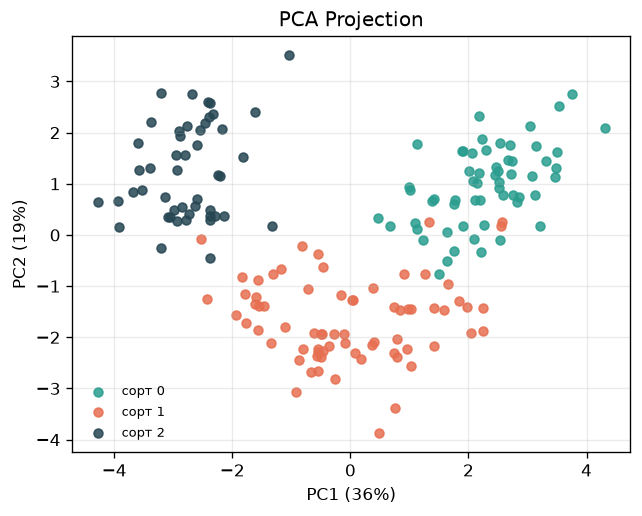

In [30]:
show("../PythonAI_Author_Lesson31_Lesson32/results/pca_projection.png")

**Що побачите.** `PCA(n_components=2)` дає ті самі `(178, 2)`. `PC1 36.2% + PC2 19.2% = 55.4%`; решти 44.6% розкиду на карті не видно. PC1 і PC2 не корелюють. PC1: `flavanoids +0.42`, `total_phenols +0.39`. PC2: `color_intensity +0.53`, `alcohol +0.48`. Рисунок — `results/pca_projection.png`, у підписах осей стоять частки дисперсії.

**Міні-завдання 7 · 3 хв.** Відкрийте свій `my_svd.py` з кроку 8. Поверніть `n_components=2`, додайте `PCA` в імпорт із `sklearn.decomposition` і замініть `TruncatedSVD(` на `PCA(`. Запустіть. Що сталося з числами `explained_variance_ratio_`? Причину ви побачите на кроці 13.

**Часта пастка:** номер компоненти — це не її частка. PC2 означає «друга за розкидом», а не «20%».

**Перевір себе:**
15. Дві осі зберігають 55.4% дисперсії. Чому сорти на карті все одно видно добре?

<a id="step-13"></a>
## Крок 13 · 0:20–0:36 · PCA руками і чим він відрізняється від SVD

У презентації 32: «Приклад · дві головні компоненти на toy-даних», «SVD vs PCA після scaler».

In [31]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_02_pca_by_hand.py")

1) PCA руками
   матриця коваріацій (13, 13), власні числа: [4.73 2.51 1.45 0.92] …
   частка кожного: [0.362 0.192 0.111 0.071] …

2) Порівняння з sklearn.decomposition.PCA
   explained_variance_ratio_: [0.362 0.192]
   різниця координат: 3.1e-15

3) Той самий PCA через SVD центрованої таблиці
   s² / (n − 1) = [4.73 2.51 1.45 0.92] — це власні числа з кроку 1
   різниця осей: 1.0e-15

4) TruncatedSVD проти PCA на масштабованому wine
   різниця координат: 9.7e-09
   StandardScaler уже відняв середнє, тому PCA більше нічого центрувати

5) Те саме без scaler (дані не центровані)
   різниця координат SVD і PCA: 759
   косинус між першою віссю SVD і вектором середніх: 0.9998
   перша вісь SVD показує, де лежить хмара відносно нуля, а не як вона розкидана
   SVD-1: від 287 до 1681;  PC1: від -469 до 933

PCA = центрування + SVD. Знак осі довільний: графік може бути дзеркальним, і це не помилка.



**Що побачите.**
1. PCA за три дії: відняти середнє → матриця коваріацій 13 × 13 → власні вектори. Власні числа `4.73, 2.51, 1.45, …`; їхні частки — це і є `explained_variance_ratio_`.
2. Координати збігаються з `sklearn.decomposition.PCA`.
3. Те саме дає SVD центрованої таблиці: `s² / (n − 1)` — ті самі власні числа.
4. На масштабованому wine `TruncatedSVD` і `PCA` відрізняються на `9.7e-09`: scaler уже відняв середнє.
5. Без scaler координати розходяться на 759. Перша вісь SVD майже збігається з вектором середніх (косинус 0.9998): вона показує, де лежить хмара відносно нуля, а не як вона розкидана.

**PCA = центрування + SVD.** Це головна формула пари.

**Перевір себе:**
16. Чому `PCA` після `StandardScaler` нічого не центрує вдруге?
17. Чому перша вісь SVD на нецентрованих даних «дивиться» на середнє?

<a id="step-14"></a>
## Крок 14 · 0:36–0:51 · SVD і PCA в одному вікні (завдання 7.1.4)

У презентації 32: «Приклад · дві панелі subplot», «Як читати схожі графіки».

In [32]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_03_svd_vs_pca.py", "--raw")

1) Один X після scaler, два алгоритми
   PCA explained_variance_ratio_ = [0.362  0.1921], сума 0.5541
   SVD explained_variance_ratio_ = [0.362  0.1921], сума 0.5541

2) Наскільки різні координати
   найбільша різниця після вирівнювання знаків: 9.7e-09
   дзеркальні осі: немає

3) Якість карти (kNN на двох координатах, 5-fold)
   SVD після scaler: 96.6%
   PCA після scaler: 96.6%
   SVD без scaler:   70.3%
   PCA без scaler:   69.1%
   PCA без scaler «пояснює» 99.98% дисперсії — але це дисперсія одного proline

4) Підсумковий рисунок: results\dimensionality_reduction_comparison.png
   Графіки однакові — це не помилка. Після scaler дані центровані, а PCA = центрування + SVD.



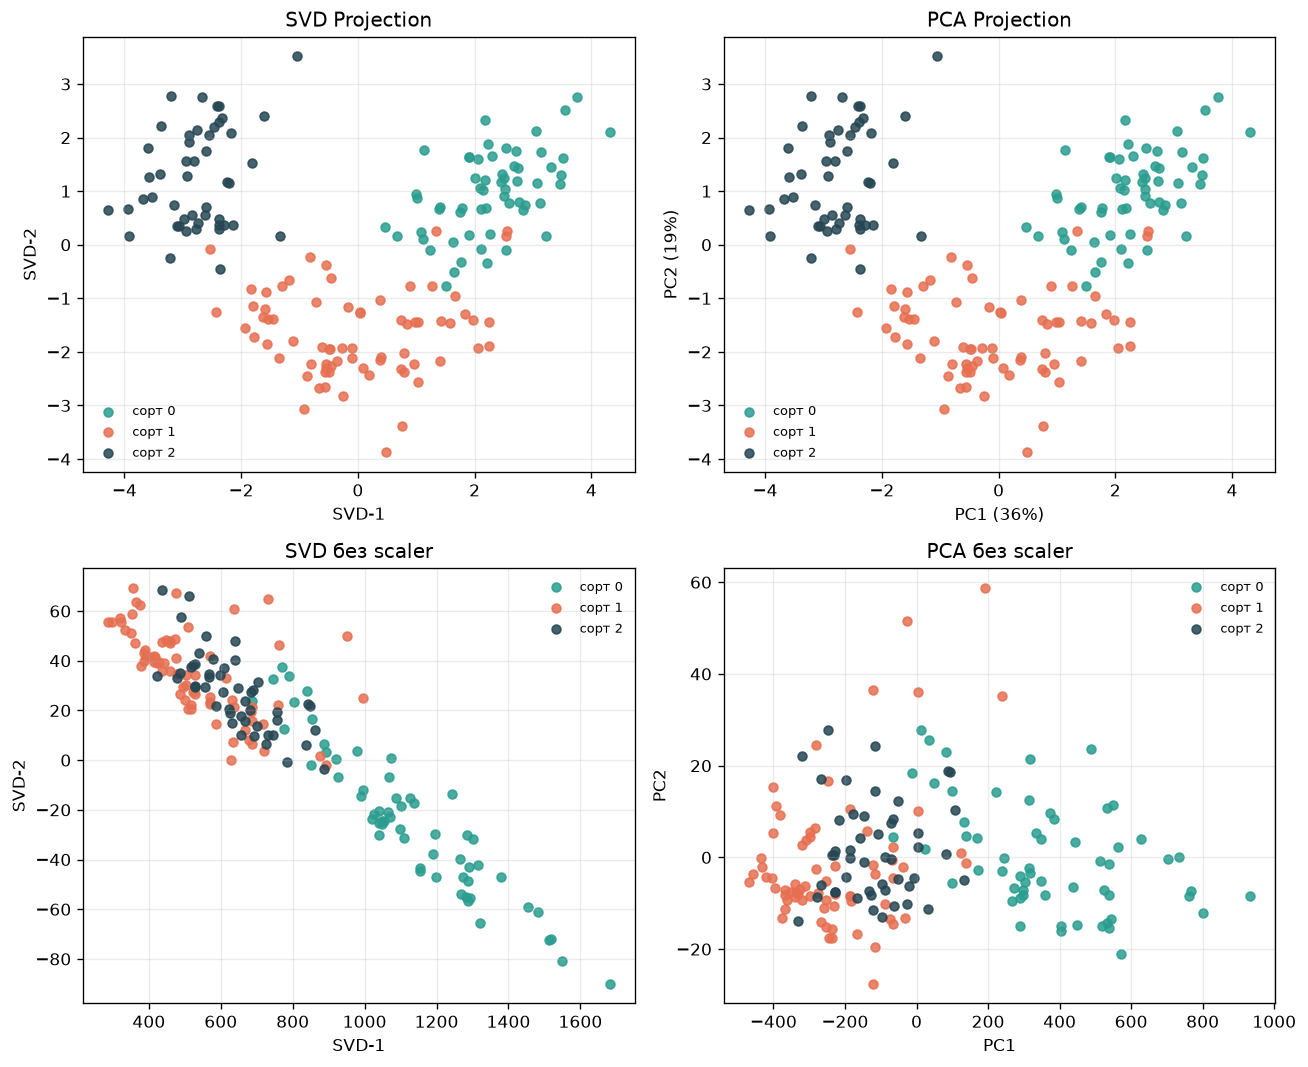

In [33]:
show("../PythonAI_Author_Lesson31_Lesson32/results/dimensionality_reduction_comparison.png")

**Що побачите.** `explained_variance_ratio_` обох моделей — `[0.362 0.1921]`, сума 0.5541. Рисунок `results/dimensionality_reduction_comparison.png`: верхній рядок — після scaler, нижній — без нього.

| Варіант | kNN на двох координатах |
|---|---|
| SVD після scaler | 96.6% |
| PCA після scaler | 96.6% |
| SVD без scaler | 70.3% |
| PCA без scaler | 69.1% |

PCA без scaler повідомляє, що дві компоненти пояснюють 99.98% дисперсії. Це дисперсія одного `proline`, а карта при цьому гірша.

**Зверніть увагу:** однакові графіки після scaler — не помилка. Дзеркальний графік теж не помилка: знак осі довільний.

**Напишіть самі.** Файл `PythonAI_Author_Lesson31_Lesson32/my_pca.py`:

[0.362  0.1921] 0.5541


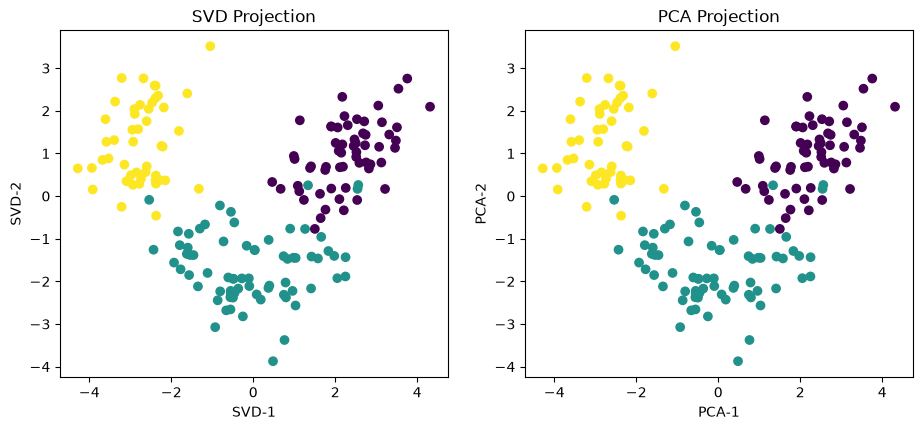

In [34]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.preprocessing import StandardScaler

df = load_wine(as_frame=True).frame
X_scaled = StandardScaler().fit_transform(df.drop(columns="target"))

Z_svd = TruncatedSVD(n_components=2, random_state=42).fit_transform(X_scaled)
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(X_scaled)
print(pca.explained_variance_ratio_.round(4), pca.explained_variance_ratio_.sum().round(4))
# Міні-завдання 8: домножте першу вісь PCA на -1 →  Z_pca[:, 0] *= -1
# Міні-завдання 9 (крок 15): надрукуйте PCA(n_components=0.95).fit(X_scaled).n_components_

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, Z, name in [(axes[0], Z_svd, "SVD"), (axes[1], Z_pca, "PCA")]:
    ax.scatter(Z[:, 0], Z[:, 1], c=df["target"])
    ax.set_title(f"{name} Projection")
    ax.set_xlabel(f"{name}-1")
    ax.set_ylabel(f"{name}-2")
plt.show()

Має надрукувати `[0.362  0.1921] 0.5541`.

**Міні-завдання 8 · 2 хв.** У своєму `my_pca.py` домножте першу вісь PCA на −1 (`Z_pca[:, 0] *= -1` перед побудовою графіка) і порівняйте дві панелі. Чи змінилась відстань між будь-якими двома винами? Чи стала карта гіршою?

**Зверніть увагу:** обидва алгоритми отримують один і той самий `X_scaled`. Якщо показуєте вікно через `plt.show()`, рисунок зберігайте до нього: після закриття вікна matplotlib збереже порожнє полотно.

**Перевір себе:**
18. Чому високе `explained_variance_ratio_` ще не означає, що карта добра?

<a id="step-15"></a>
## Крок 15 · 0:51–1:05 · Скільки компонент лишати

У презентації 32: «Додатково: скільки компонент лишати», «Додатково: scree plot».

In [35]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_04_how_many_components.py")

1) Усі 13 компонент: частка дисперсії і накопичена сума
   PC1   36.2%  разом  36.2%  ██████████████████████
   PC2   19.2%  разом  55.4%  ████████████
   PC3   11.1%  разом  66.5%  ███████
   PC4    7.1%  разом  73.6%  ████
   PC5    6.6%  разом  80.2%  ████
   PC6    4.9%  разом  85.1%  ███
   PC7    4.2%  разом  89.3%  ███
   PC8    2.7%  разом  92.0%  ██
   PC9    2.2%  разом  94.2%  █
   PC10   1.9%  разом  96.2%  █
   PC11   1.7%  разом  97.9%  █
   PC12   1.3%  разом  99.2%  █
   PC13   0.8%  разом 100.0%  

2) Скільки компонент треба, щоб зберегти задану частку
   80% → 5 компонент
   90% → 8 компонент
   95% → 10 компонент
   PCA(n_components=0.90) сам вибрав 8
   графік: results\scree_plot.png

3) PCA як крок перед класифікацією (LogisticRegression, 5-fold)
    k   точність
    1   84.8%
    2   95.5%
    3   96.6%
    5   97.8%
    8   97.8%
   13   98.3%
   без PCA: 98.3%

Scaler і PCA стоять усередині Pipeline: у кожному fold вони навчаються лише на train-частині.
Якщо зро

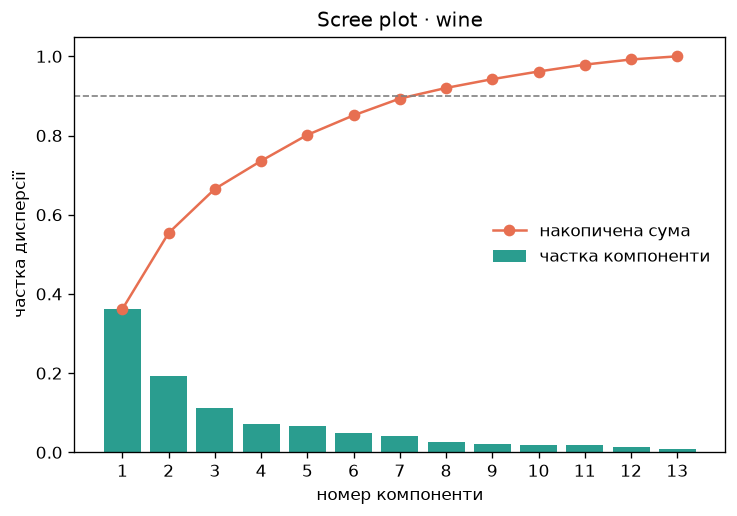

In [36]:
show("../PythonAI_Author_Lesson31_Lesson32/results/scree_plot.png")

**Що побачите.** Частки всіх 13 компонент і рисунок `results/scree_plot.png`. 80% дисперсії зберігають 5 компонент, 90% — 8, 95% — 10. `PCA(n_components=0.90)` сам вибирає 8.

PCA як крок перед класифікацією (`Pipeline`: scaler → PCA → LogisticRegression, 5-fold):

| Компонент | Точність |
|---|---|
| 1 | 84.8% |
| 2 | 95.5% |
| 3 | 96.6% |
| 5 | 97.8% |
| 13 | 98.3% |
| без PCA | 98.3% |

**Міні-завдання 9 · 2 хв.** У `my_pca.py` додайте рядок `print(PCA(n_components=0.95).fit(X_scaled).n_components_)`. Скільки компонент потрібно для 95% розкиду? А для 99%?

**Зверніть увагу:** scaler і PCA стоять усередині `Pipeline`, тому в кожному fold навчаються лише на train-частині. Якщо зробити `fit_transform` на всій таблиці до поділу, тестові рядки вплинуть на осі. Це leakage, як на парі 13.

**Перевір себе:**
19. Для нового вина викликають `transform`, а не `fit_transform`. Чому?
20. На wine PCA не підняв точність. Навіщо тоді зменшувати розмірність перед класифікацією?

<a id="step-16"></a>
## Крок 16 · 1:05–1:20 · Практика

[Lesson32_tasks.md](../PythonAI_Author_Lesson31_Lesson32/Lesson32_tasks.md), завдання 2, пункти 1–3: вікно 2 × 2 зі `StandardScaler` і `MinMaxScaler`, найбільша різниця координат, таблиця.

Якщо важко — [Lesson31_tasks.md](../PythonAI_Author_Lesson31_Lesson32/Lesson31_tasks.md), завдання 2, пункти 1–3 на wine.

Перед тим як показати результат, перевірте:
- [ ] у `X` немає стовпця `target`;
- [ ] обидва алгоритми отримали той самий масштабований `X`;
- [ ] надруковано `explained_variance_ratio_`;
- [ ] рисунок збережено у файл.

<a id="step-17"></a>
## Крок 17 · 1:20–1:30 · Перевір себе і підсумок

21. Що шукає PCA?
22. Чому порівняння SVD і PCA чесне лише на одному `X_scaled`?
23. Чому SVD і PCA можуть виглядати однаково?

**Підсумок.**
1. Зниження розмірності шукає кілька нових осей, які зберігають якомога більше розкиду таблиці. Відповіді (`target`) воно не бачить.
2. Перед SVD і PCA ознаки масштабують, інакше все вирішує стовпець з найбільшими числами.
3. SVD: `X = U·S·Vᵀ`; лишаємо `k` найбільших сингулярних чисел.
4. PCA = центрування + SVD. Після `StandardScaler` обидва алгоритми дають ту саму карту.
5. Кількість компонент вибирають під задачу: 2 для графіка, 90% дисперсії або найкраща точність — для моделі.

На парі 28 PCA була готовою кнопкою, яка зберегла 20% розкиду. Тепер ви знаєте, що це за кнопка і як порахувати втрату.

**Домашнє:** [Lesson31_homework.md](../PythonAI_Author_Lesson31_Lesson32/Lesson31_homework.md), [Lesson32_homework.md](../PythonAI_Author_Lesson31_Lesson32/Lesson32_homework.md).

**Наступна пара** — кластеризація K-Means: на цій самій карті алгоритм сам шукатиме групи, вже без кольорів-підказок.